In [ ]:
!pip install -q gensim nltk emoji matplotlib pandas tqdm

import os
os.environ['PYTHONHASHSEED'] = '0'
import random
random.seed(42)
import numpy as np
np.random.seed(42)

import pandas as pd
import re
import string
import emoji
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('stopwords')

from gensim.models import CoherenceModel, LdaModel
from gensim.corpora import Dictionary
from gensim.models.phrases import Phrases, Phraser
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
FILE_CSV1 = "/content/HOTD Teaser Trailer comment Scraped(Data).csv"
COLUMN_KOMENTAR = "comment"                # Diubah dari 'title' ke 'comment' agar memproses komentar user
OUTPUT_DIR = "/content/final_LDA"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
print("="*60)
print("MEMBACA DAN MENGGABUNGKAN CSV")

# Menggunakan encoding='latin-1' untuk menghindari UnicodeDecodeError
df = pd.read_csv(FILE_CSV1, encoding='latin-1')

print(f"File shape: {df.shape}")

# Pastikan file memiliki kolom yang sesuai
if COLUMN_KOMENTAR not in df.columns:
    raise ValueError(f"Pastikan CSV memiliki kolom '{COLUMN_KOMENTAR}'")

print("Contoh data awal:")
print(df.head(3))

MEMBACA DAN MENGGABUNGKAN CSV
File shape: (2489, 10)
Contoh data awal:
                author                                            comment  \
0          @MrShadowCX  I see a lot of people saying the skull she has...   
1  @clintoniyizoba1859               Book readers. Was that the Preacher?   
2            @djsatane                      HBO too cheap to upload in 4k   

      type  voteCount  replyCount publishedTimeText  hasCreatorHeart  \
0  comment          0           0    19 minutes ago            False   
1  comment          0           0        1 hour ago            False   
2  comment          0           0       4 hours ago            False   

   authorIsChannelOwner                                              title  \
0                 False  House of the Dragon Season 3 | Official Teaser...   
1                 False  House of the Dragon Season 3 | Official Teaser...   
2                 False  House of the Dragon Season 3 | Official Teaser...   

                  

In [ ]:
print("\n" + "="*60)
print("PEMBERSIHAN DATA")

# Simpan jumlah sebelum cleaning
jumlah_sebelum = len(df)

# Hapus baris kosong/NaN awal
df.dropna(subset=[COLUMN_KOMENTAR], inplace=True)
df[COLUMN_KOMENTAR] = df[COLUMN_KOMENTAR].astype(str).str.strip()
df = df[df[COLUMN_KOMENTAR] != ""]

def clean_text(text):
    text = str(text)
    # Hapus URL
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Hapus emoji (library emoji)
    text = emoji.replace_emoji(text, replace='')
    # Hapus mention, hashtag
    text = re.sub(r'@\w+|#\w+', '', text)
    # Hapus HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Hapus timestamps
    text = re.sub(r'\b(\d+\s+(minute|hour|day|week|month|year)s?\s+ago)\b', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\b(\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}|\d{1,2}:\d{2}(:\d{2})?)\b', '', text)
    # Hapus tanda baca
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    # Lowercase
    text = text.lower()
    return text

tqdm.pandas(desc="Cleaning")
df[COLUMN_KOMENTAR] = df[COLUMN_KOMENTAR].progress_apply(clean_text)

# CRITICAL: Hapus baris yang menjadi kosong setelah cleaning
df = df[df[COLUMN_KOMENTAR].str.strip() != ""]

# Hapus komentar yang kurang dari 3 kata (membuang komentar yang hanya 1 atau 2 kata)
df = df[df[COLUMN_KOMENTAR].apply(lambda x: len(x.split()) >= 3)]

# Hapus komentar yang terlalu pendek (< 3 karakter secara total)
df = df[df[COLUMN_KOMENTAR].apply(len) >= 3]

jumlah_sesudah = len(df)
print(f"Jumlah data sebelum cleaning: {jumlah_sebelum}")
print(f"Jumlah data sesudah cleaning: {jumlah_sesudah}")
print(f"Data yang dibuang: {jumlah_sebelum - jumlah_sesudah}")


PEMBERSIHAN DATA


Cleaning: 100%|██████████| 2454/2454 [00:00<00:00, 12143.81it/s]

Jumlah data sebelum cleaning: 2489
Jumlah data sesudah cleaning: 2137
Data yang dibuang: 352


In [ ]:
print("\n" + "="*60)
print("VERIFIKASI KEBERSIHAN DATA")

# Periksa kembali keberadaan URL, emoji, spasi ganda, dan baris kosong
teks_bersih = df[COLUMN_KOMENTAR].tolist()

# Cek URL
url_pattern = re.compile(r'http\S+|www\S+|https\S+')
sisa_url = sum(bool(url_pattern.search(teks)) for teks in teks_bersih)
print(f"Jumlah teks yang masih mengandung URL: {sisa_url}")

# Cek emoji
sisa_emoji = sum(emoji.emoji_count(teks) > 0 for teks in teks_bersih)
print(f"Jumlah teks yang masih mengandung emoji: {sisa_emoji}")

# Cek mention/tag (@ atau #)
tag_pattern = re.compile(r'@\w+|#\w+')
sisa_tag = sum(bool(tag_pattern.search(teks)) for teks in teks_bersih)
print(f"Jumlah teks yang masih mengandung tag (@/#): {sisa_tag}")

# Cek Timestamps (format: 19 minutes ago, 1 hour ago, atau 00:00)
time_pattern = re.compile(r'\b(\d+\s+(minute|hour|day|week|month|year)s?\s+ago)\b|\b(\d{1,2}:\d{2})\b', re.IGNORECASE)
sisa_time = sum(bool(time_pattern.search(teks)) for teks in teks_bersih)
print(f"Jumlah teks yang masih mengandung timestamp: {sisa_time}")

# Cek spasi berlebih (lebih dari satu spasi berurutan)
spasi_pattern = re.compile(r'\s{2,}')
sisa_spasi = sum(bool(spasi_pattern.search(teks)) for teks in teks_bersih)
print(f"Jumlah teks yang masih memiliki spasi berlebih: {sisa_spasi}")

# Cek baris kosong
baris_kosong = sum(1 for teks in teks_bersih if not teks.strip())
print(f"Jumlah baris kosong setelah cleaning: {baris_kosong}")

# Cek NaN
nan_tersisa = df[COLUMN_KOMENTAR].isna().sum()
print(f"Jumlah nilai NaN: {nan_tersisa}")

# Tampilkan beberapa contoh hasil cleaning
print("\nContoh teks setelah cleaning (5 teratas):")
for i in range(min(5, len(df))):
    print(f"[{i}] {df.iloc[i][COLUMN_KOMENTAR][:200]}...")

if sisa_url == 0 and sisa_emoji == 0 and sisa_tag == 0 and sisa_time == 0 and sisa_spasi == 0 and baris_kosong == 0 and nan_tersisa == 0:
    print("\n✅ Data sudah bersih sempurna! Tidak ada URL, emoji, tag, timestamp, spasi berlebih, atau baris kosong.")
else:
    print("\n⚠️ Masih ada data yang perlu dibersihkan lebih lanjut. Periksa kembali fungsi cleaning.")


VERIFIKASI KEBERSIHAN DATA
Jumlah teks yang masih mengandung URL: 0
Jumlah teks yang masih mengandung emoji: 0
Jumlah teks yang masih mengandung tag (@/#): 0
Jumlah teks yang masih mengandung timestamp: 0
Jumlah teks yang masih memiliki spasi berlebih: 0
Jumlah baris kosong setelah cleaning: 0
Jumlah nilai NaN: 0

Contoh teks setelah cleaning (5 teratas):
[0] i see a lot of people saying the skull she has is from her son and shes giving him a proper targaryen funeral with burning the skull in the fireplace the skull is not her sons its from her father w...
[1] book readers was that the preacher...
[2] hbo too cheap to upload in 4k...
[3] im scared but ready...
[4] the entire trailer had rhaenyra just pacing about and giving intense looks...

✅ Data sudah bersih sempurna! Tidak ada URL, emoji, tag, timestamp, spasi berlebih, atau baris kosong.


In [ ]:
print("\n" + "="*60)
print("TOKENISASI, BIGRAM, DAN NORMALISASI")

# Stopwords Indonesia + Inggris
nltk.download('punkt_tab')
stop_words = set(stopwords.words('indonesian') + stopwords.words('english'))
custom_stopwords = {'malaysian','yg', 'nya', 'di', 'ke', 'dan', 'itu', 'sih', 'aja', 'dong', 'deh', 'lah', 'kok', 'nih', 'ya', 'ga', 'gk', 'tdk', 'tak', 'batik', 'mybatik','teja', 'studio','appointment','row','boutique','workshop','malaysia', 'kuala','tunku', 'taman', 'stories' }
stop_words.update(custom_stopwords)

# Dictionary pemetaan singkatan
slang_dict = {
    "tf": "the fuck",
    "wth": "what the hell",
    "im": "i am",
    "cant": "can not",
    "dont": "do not",
    "u": "you",
    "r": "are",
    "brb": "be right back",
    "btw": "by the way",
    "omg": "oh my god",
    "it's": "it is",
    "i'm": "i am",
    "you're": "you are",
}

def normalize_slang(text):
    words = text.split()
    normalized_words = [slang_dict.get(word, word) for word in words]
    return " ".join(normalized_words)

# Tokenisasi dan pembersihan token
def tokenize(text):
    # Normalisasi singkatan terlebih dahulu
    text = normalize_slang(text)
    tokens = word_tokenize(text)
    # Filter stopwords dan karakter pendek
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    return tokens

tqdm.pandas(desc="Tokenizing")
df['tokens'] = df[COLUMN_KOMENTAR].progress_apply(tokenize)

# Hapus baris dengan tokens kosong
df = df[df['tokens'].apply(len) > 0]

# Membuat bigram model
token_list = df['tokens'].to_list()
bigram = Phrases(token_list, min_count=5, threshold=100)
bigram_phraser = Phraser(bigram)

# Aplikasi bigram ke setiap dokumen
tqdm.pandas(desc="Bigramming")
df['tokens_bigram'] = df['tokens'].progress_apply(lambda x: bigram_phraser[x])

# Simpan tokens sebagai final
documents = df['tokens_bigram'].to_list()

print(f"Jumlah dokumen final: {len(documents)}")
print("Contoh 2 dokumen hasil preprocessing:")
for i, doc in enumerate(documents[:2]):
    print(f"Dok {i}: {' '.join(doc)}")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!



TOKENISASI, BIGRAM, DAN NORMALISASI


Bigramming: 100%|██████████| 2133/2133 [00:00<00:00, 12153.34it/s]

Jumlah dokumen final: 2133
Contoh 2 dokumen hasil preprocessing:
Dok 0: see lot people saying skull son shes giving proper targaryen funeral burning skull fireplace skull sons its father let rot bed left thats see shot burning bed
Dok 1: book readers preacher


In [ ]:
print("\n" + "="*60)
print("MEMBUAT DICTIONARY DAN CORPUS")

dictionary = Dictionary(documents)
# Filter ekstrim: kata yang muncul di < 5 dokumen atau > 50% dokumen
dictionary.filter_extremes(no_below=2, no_above=0.5)
corpus = [dictionary.doc2bow(text) for text in documents]

print(f"Jumlah token unik di dictionary: {len(dictionary)}")
print(f"Jumlah total dokumen di corpus: {len(corpus)}")

# Simpan file pendukung
dictionary.save(os.path.join(OUTPUT_DIR, 'dictionary.gensim'))
pd.Series(documents).to_csv(os.path.join(OUTPUT_DIR, 'tokens_final.csv'), index=False, header=['tokens'])


MEMBUAT DICTIONARY DAN CORPUS
Jumlah token unik di dictionary: 1559
Jumlah total dokumen di corpus: 2133



MENCARI JUMLAH TOPIK OPTIMAL (SUPER STABIL)
Jumlah Topik = 2 | Skor Koherensi = 0.4454
Jumlah Topik = 3 | Skor Koherensi = 0.5989
Jumlah Topik = 4 | Skor Koherensi = 0.3823
Jumlah Topik = 5 | Skor Koherensi = 0.3525
Jumlah Topik = 6 | Skor Koherensi = 0.3281
Jumlah Topik = 7 | Skor Koherensi = 0.3534
Jumlah Topik = 8 | Skor Koherensi = 0.344
Jumlah Topik = 9 | Skor Koherensi = 0.3599
Jumlah Topik = 10 | Skor Koherensi = 0.3814
Jumlah Topik = 11 | Skor Koherensi = 0.3767
Jumlah Topik = 12 | Skor Koherensi = 0.379
Jumlah Topik = 13 | Skor Koherensi = 0.3919
Jumlah Topik = 14 | Skor Koherensi = 0.3928

Jumlah topik optimal: 3


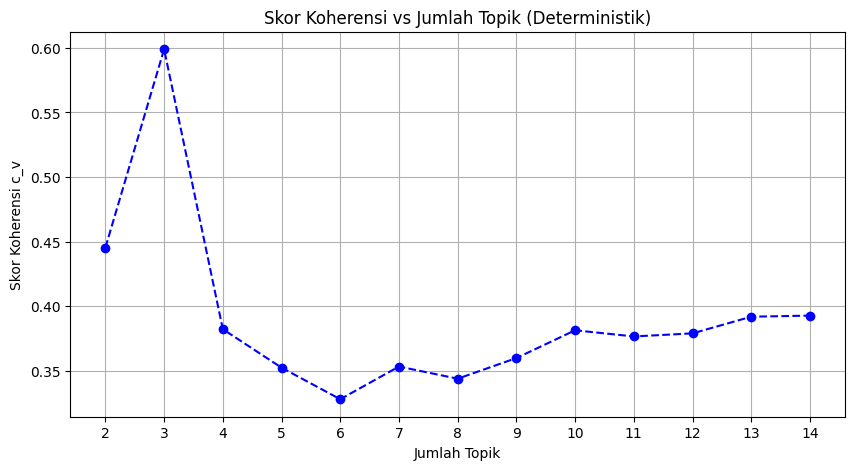

In [ ]:
import os
os.environ['PYTHONHASHSEED'] = '0'
import random
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import LdaModel, CoherenceModel

# Kunci ulang seed untuk konsistensi absolut
random.seed(42)
np.random.seed(42)

print("\n" + "="*60)
print("MENCARI JUMLAH TOPIK OPTIMAL (SUPER STABIL)")

def compute_coherence_values(dictionary, corpus, texts, limit, start=2, step=1):
    coherence_values = []
    for num_topics in range(start, limit, step):
        # Re-seed tiap iterasi (proteksi tambahan)
        np.random.seed(42)
        random.seed(42)

        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            random_state=42,
            passes=50,
            iterations=200,
            chunksize=100,
            eval_every=None,
            update_every=0,          # batch learning = 100% deterministik
            alpha='auto',
            eta='auto',
        )
        coherencemodel = CoherenceModel(
            model=model,
            texts=texts,
            dictionary=dictionary,
            coherence='c_v',
            processes=1              # pastikan single‑threaded
        )
        cv = coherencemodel.get_coherence()
        coherence_values.append(cv)
    return coherence_values

# Pastikan corpus dan texts adalah list (bukan generator/stream)
corpus = list(corpus)
texts = list(documents)

start = 2
limit = 15
step = 1

coherence_values = compute_coherence_values(
    dictionary=dictionary,
    corpus=corpus,
    texts=texts,
    limit=limit,
    start=start,
    step=step
)

# Tampilkan skor
x = range(start, limit, step)
for m, cv in zip(x, coherence_values):
    print(f"Jumlah Topik = {m} | Skor Koherensi = {round(cv, 4)}")

optimal_num_topics = x[coherence_values.index(max(coherence_values))]
print(f"\nJumlah topik optimal: {optimal_num_topics}")

# Plot
plt.figure(figsize=(10,5))
plt.plot(x, coherence_values, marker='o', linestyle='--', color='b')
plt.xlabel("Jumlah Topik")
plt.ylabel("Skor Koherensi c_v")
plt.title("Skor Koherensi vs Jumlah Topik (Deterministik)")
plt.xticks(x)
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, 'coherence_plot.png'))
plt.show()

In [ ]:
print("\n" + "="*60)
print(f"MELATIH LDA DENGAN {optimal_num_topics} TOPIK")

final_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=optimal_num_topics,
    random_state=42,
    passes=100,        # lebih banyak pass untuk hasil final
    iterations=400,
    chunksize=100,
    eval_every=None,
)

final_model.save(os.path.join(OUTPUT_DIR, 'final_lda_model.gensim'))



MELATIH LDA DENGAN 3 TOPIK


In [ ]:
print("\n" + "="*60)
print("DISTRIBUSI KATA PER TOPIK (TOP 10 KATA)")

topic_info = []
for idx, topic in final_model.show_topics(formatted=False, num_words=10):
    total_prob = sum(prob for _, prob in topic)
    words = [word for word, prob in topic]
    percents = [round(prob * 100, 2) for _, prob in topic]
    topic_info.append({'Topik': idx, 'Kata': words, 'Probabilitas (%)': percents})
    print(f"\nTopik {idx}:")
    for word, perc in zip(words, percents):
        print(f"  {word}: {perc}%")

# Simpan distribusi kata
df_topics = pd.DataFrame(topic_info)
df_topics.to_csv(os.path.join(OUTPUT_DIR, 'topic_word_distribution.csv'), index=False)


DISTRIBUSI KATA PER TOPIK (TOP 10 KATA)

Topik 0:
  season: 9.149999618530273%
  like: 2.809999942779541%
  dragon: 2.0299999713897705%
  last: 1.6699999570846558%
  good: 1.649999976158142%
  looks: 1.5700000524520874%
  hope: 1.409999966621399%
  trailer: 1.2400000095367432%
  time: 1.2100000381469727%
  house: 1.2000000476837158%

Topik 1:
  wait: 2.6700000762939453%
  see: 2.369999885559082%
  rhaenyra: 2.240000009536743%
  daemon: 1.7799999713897705%
  battle: 1.559999942779541%
  story: 1.25%
  war: 1.1799999475479126%
  going: 1.1799999475479126%
  think: 1.159999966621399%
  targaryen: 1.1299999952316284%

Topik 2:
  show: 3.1700000762939453%
  aemond: 2.0199999809265137%
  series: 1.4500000476837158%
  people: 1.3700000047683716%
  aegon: 1.1399999856948853%
  another: 1.1100000143051147%
  please: 1.100000023841858%
  watch: 1.059999942779541%
  gon: 1.0199999809265137%
  still: 0.8999999761581421%



KONTRIBUSI TOPIK DI DALAM KORPUS
Topik 0: 38.0% kontribusi (rata-rata probabilitas)
Topik 1: 31.43% kontribusi (rata-rata probabilitas)
Topik 2: 30.57% kontribusi (rata-rata probabilitas)


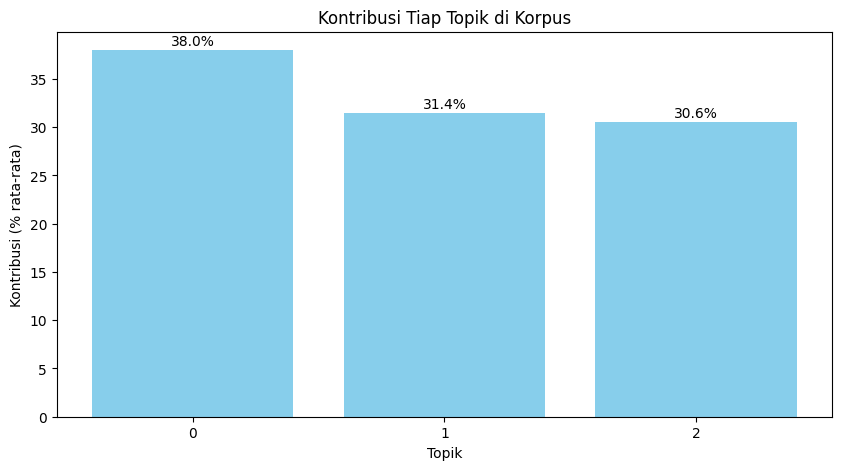


Semua hasil telah disimpan di folder: /content/final_LDA
File penting: dictionary.gensim, final_lda_model.gensim, topic_word_distribution.csv, topic_contributions.csv, coherence_plot.png, dll.


In [ ]:
print("\n" + "="*60)
print("KONTRIBUSI TOPIK DI DALAM KORPUS")

# Ambil probabilitas topik untuk setiap dokumen
doc_topics = [final_model.get_document_topics(bow, minimum_probability=0.0) for bow in corpus]
# Rata-rata probabilitas tiap topik di semua dokumen
topic_contrib = np.zeros(optimal_num_topics)
for doc_dist in doc_topics:
    for topic_id, prob in doc_dist:
        topic_contrib[topic_id] += prob
topic_contrib /= len(doc_topics)  # rata-rata

for i, contrib in enumerate(topic_contrib):
    print(f"Topik {i}: {round(contrib*100, 2)}% kontribusi (rata-rata probabilitas)")

# Simpan kontribusi
contrib_df = pd.DataFrame({
    'Topik': list(range(optimal_num_topics)),
    'Kontribusi_RataRata_Probabilitas': topic_contrib
})
contrib_df.to_csv(os.path.join(OUTPUT_DIR, 'topic_contributions.csv'), index=False)

# Diagram batang kontribusi
plt.figure(figsize=(10,5))
plt.bar(range(optimal_num_topics), topic_contrib*100, color='skyblue')
plt.xlabel("Topik")
plt.ylabel("Kontribusi (% rata-rata)")
plt.title("Kontribusi Tiap Topik di Korpus")
plt.xticks(range(optimal_num_topics))
for i, v in enumerate(topic_contrib*100):
    plt.text(i, v+0.5, f"{v:.1f}%", ha='center')
plt.savefig(os.path.join(OUTPUT_DIR, 'topic_contributions_plot.png'))
plt.show()

# Simpan ringkasan
with open(os.path.join(OUTPUT_DIR, 'ringkasan_hasil.txt'), 'w') as f:
    f.write(f"Jumlah topik optimal: {optimal_num_topics}\n")
    f.write(f"Skor koherensi tertinggi: {max(coherence_values):.4f}\n")
    f.write("\nDistribusi Kata per Topik (10 teratas):\n")
    for idx, row in df_topics.iterrows():
        f.write(f"Topik {row['Topik']}: {', '.join(row['Kata'])}\n")
    f.write("\nKontribusi Topik:\n")
    for i, c in enumerate(topic_contrib):
        f.write(f"Topik {i}: {c*100:.2f}%\n")

print(f"\nSemua hasil telah disimpan di folder: {OUTPUT_DIR}")
print("File penting: dictionary.gensim, final_lda_model.gensim, topic_word_distribution.csv, topic_contributions.csv, coherence_plot.png, dll.")

In [ ]:
print("\n" + "="*60)
print("OUTPUT KOMENTAR CONTOH PER TOPIK")

# 1. Buat DataFrame df_topic_sents_keywords terlebih dahulu
def format_topics_sentences(ldamodel, corpus, texts):
    sent_topics_df = pd.DataFrame()

    # Dapatkan topik utama di setiap dokumen
    for i, row in enumerate(ldamodel[corpus]):
        row = sorted(row, key=lambda x: (x[1]), reverse=True)
        # Ambil Topik Dominan, Kontribusi Percen, dan Kata Kunci
        for j, (topic_num, prop_topic) in enumerate(row):
            if j == 0:  # => topik dominan
                wp = ldamodel.show_topic(topic_num)
                topic_keywords = ", ".join([word for word, prop in wp])
                sent_topics_df = pd.concat([sent_topics_df, pd.DataFrame([[int(topic_num), round(prop_topic,4), topic_keywords]])], ignore_index=True)
            else:
                break
    sent_topics_df.columns = ['Dominant_Topic', 'Perc_Contribution', 'Topic_Keywords']

    # Tambahkan teks asli ke akhir output
    contents = pd.Series(texts)
    sent_topics_df = pd.concat([sent_topics_df, contents], axis=1)
    return sent_topics_df

# Ambil teks asli dari dataframe df (yang sudah di-filter barisnya sama dengan corpus)
df_topic_sents_keywords = format_topics_sentences(ldamodel=final_model, corpus=corpus, texts=df[COLUMN_KOMENTAR].tolist())

# Beri nama kolom yang sesuai
df_topic_sents_keywords.columns = ['Dominant_Topic', 'Perc_Contribution', 'Topic_Keywords', 'Original_Comment']

# 2. Tampilkan contoh komentar untuk setiap topik
num_examples_per_topic = 10

for i in range(optimal_num_topics):
    print(f"\n--- Contoh Komentar untuk Topik {i} ---")
    # Ambil komentar unik untuk topik ini
    topic_comments = df_topic_sents_keywords[df_topic_sents_keywords['Dominant_Topic'] == i]['Original_Comment'].drop_duplicates().head(num_examples_per_topic)

    if not topic_comments.empty:
        for idx, comment in enumerate(topic_comments):
            print(f"  {idx+1}. {comment}")
    else:
        print("  Tidak ada komentar yang ditemukan untuk topik ini.")


OUTPUT KOMENTAR CONTOH PER TOPIK

--- Contoh Komentar untuk Topik 0 ---
  1. book readers was that the preacher
  2. im scared but ready
  3. the entire trailer had rhaenyra just pacing about and giving intense looks
  4. can anyone figure out who that blue dragon is in the second shot looks like its in the vale but it does not look like sheepstealer at all to me it looks more like tessarion perhaps even dreamfyre
  5. season 2 was so damn good
  6. music sounded like grenade whistle from jersey shore
  7. this time just dont nag release all episodes at once
  8. wow guys were finally getting season 2
  9. its about f time finally
  10. the teaser was even better than the trailer

--- Contoh Komentar untuk Topik 1 ---
  1. from that screaming editing daaaamn
  2. hotd is too tame and vanilla for me
  3. criston cole looking younger than he did in season 1 as everybody wrinkles up around him
  4. the targaryens are a savage
  5. i cant wait for this
  6. so they have thanks for lettin